# Homework 4

## Misleading Visualization

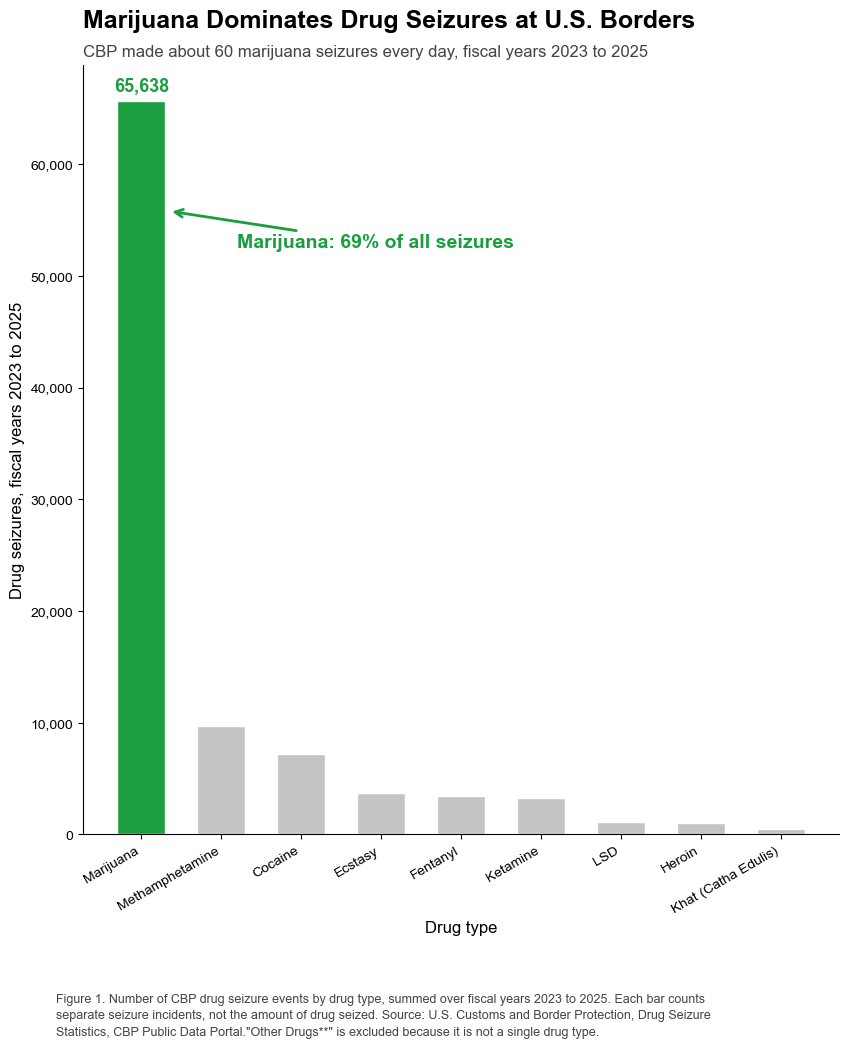

In [ ]:
# Make bars tall, thin
fig, ax = plt.subplots(figsize=(9, 11))
colors = ["#1a9e3f" if d == "Marijuana" else "#c4c4c4" for d in ev_total.index]
bars = ax.bar(ev_total.index, ev_total.values, color=colors,
              edgecolor="white", width=0.6)

# Only highlight marijuana
ax.text(bars[0].get_x() + bars[0].get_width() / 2, ev_total["Marijuana"] + 900,
        f"{ev_total['Marijuana']:,.0f}", ha="center", fontsize=13,
        fontweight="bold", color="#1a9e3f")

ax.annotate(f"Marijuana: {share['Marijuana']:.0f}% of all seizures",
            xy=(0.35, ev_total["Marijuana"] * 0.85),            # CHANGED: arrow fits thinner bar
            xytext=(1.2, ev_total["Marijuana"] * 0.80),
            fontsize=14, fontweight="bold", color="#1a9e3f",
            arrowprops=dict(arrowstyle="->", color="#1a9e3f", lw=2))

## Honest Visualization

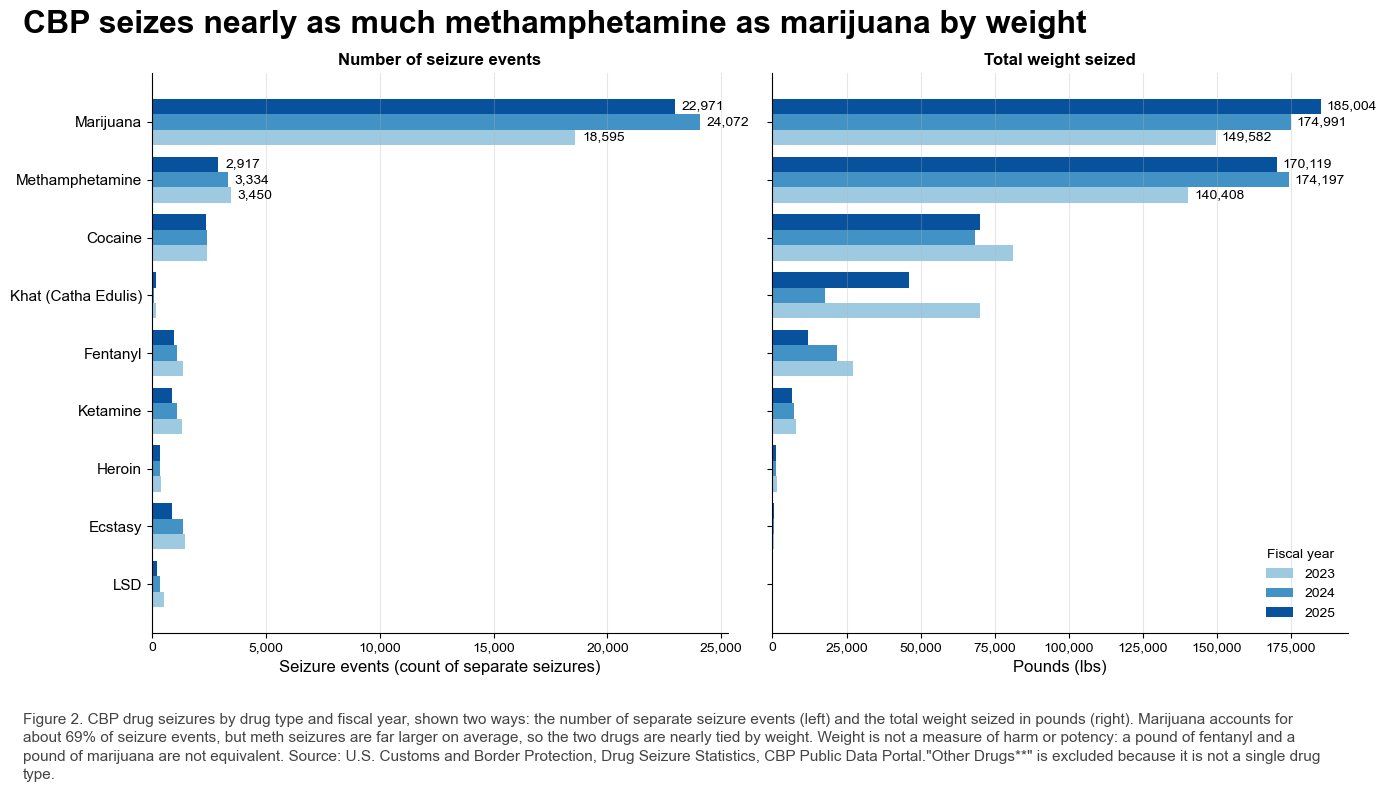

Drug Type
Marijuana              65638
Methamphetamine         9701
Cocaine                 7164
Ecstasy                 3721
Fentanyl                3426
Ketamine                3275
LSD                     1116
Heroin                  1050
Khat (Catha Edulis)      474
dtype: int64

Drug Type
Marijuana              68.7
Methamphetamine        10.2
Cocaine                 7.5
Ecstasy                 3.9
Fentanyl                3.6
Ketamine                3.4
LSD                     1.2
Heroin                  1.1
Khat (Catha Edulis)     0.5
dtype: float64

FY                       2023      2024      2025
Drug Type                                        
Cocaine               81085.0   68215.0   70080.0
Ecstasy                 649.0     609.0     441.0
Fentanyl              27023.0   21889.0   12027.0
Heroin                 1511.0    1161.0    1258.0
Ketamine               7831.0    7263.0    6578.0
Khat (Catha Edulis)   70044.0   17621.0   46245.0
LSD                      11.0      14

In [ ]:
# Plotting events and weight of drugs seized side-by-side
for i, fy in enumerate(years):
    off = (i - 1) * h
    axL.barh(y + off, events.loc[order, fy], height=h, color=year_colors[i], label=f"{fy}")
    axR.barh(y + off, pounds.loc[order, fy], height=h, color=year_colors[i], label=f"{fy}")

axL.set_yticks(y)
axL.set_yticklabels(order, fontsize=11)
axL.set_title("Number of seizure events", fontsize=12, fontweight="bold")
axL.set_xlabel("Seizure events (count of separate seizures)", fontsize=12)
axR.set_title("Total weight seized", fontsize=12, fontweight="bold")
axR.set_xlabel("Pounds (lbs)", fontsize=12)
for a in (axL, axR):
    a.spines[["top", "right"]].set_visible(False)
    a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    a.grid(axis="x", alpha=0.3)

# Label the values for marijuana and meth (most comporable)
for d in ["Marijuana", "Methamphetamine"]:
    j = list(order).index(d)
    for i, fy in enumerate(years):
        off = (i - 1) * h
        axL.text(events.loc[d, fy] + 300, j + off, f"{events.loc[d, fy]:,.0f}",
                 va="center", fontsize=10)
        axR.text(pounds.loc[d, fy] + 2000, j + off, f"{pounds.loc[d, fy]:,.0f}",
                 va="center", fontsize=10)

## Obfuscation Paragraph
The data was obfuscated and Marijuana was shown to have significantly been the most seized drug by counting solely number of seizures instead of the amount of weight seized. Relabeling each count of event formally as "drug seizures" also serves to count each event with equal importance, when one event could be a very minor drug seizure while another could be a big drug bust. Including just the number 65638 and none of the other event counts makes the number of drug seizures for Marijuana seem disproportionately big. Elongating the chart also made it seem like Marijuana was the most seized drug overall, instead of by weight. Overall, counting of the drug seizures by number of events rather than by the weight of the drug seized makes it seem like more than half of the drug seizures, a majority, were solely Marijuana. When considering weight in addition to number of drug seizure events, the amount of Methamphetamine seized was comparable to the amount of Marijuana seized and the amount of Cocaine in weight was nearly half the weight of Marijuana seized, for each fiscal year.

## AI Statement
I used Claude. I chose the CBP Drug Seizure dataset and made initial charts comparing seizure events with pounds seized. Claude suggested framing the pair around marijuana as the dominant drug when really, it is closely tied with meth by weight. It wrote most of the final plotting code with colorings and helped me create side-by-side bar charts of weight vs event count. It also helped me phrase the captions. I wrote the final obfuscation paragraph and edited the graphs to make it more readable by changing the font and caption sizes.